In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df =pd.read_csv("/content/Salary_Data.csv")
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [ ]:
df.tail()

,YearsExperience,Salary
25,9.0,105582.0
26,9.5,116969.0
27,9.6,112635.0
28,10.3,122391.0
29,10.5,121872.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [ ]:
df.shape

(30, 2)

In [ ]:
df.dtypes

,0
YearsExperience,float64
Salary,float64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


In [ ]:
X = df.iloc[:,:-1].values
Y = df.iloc[:,-1].values

In [ ]:
X

array([[ 1.1],
       [ 1.3],
       [ 1.5],
       [ 2. ],
       [ 2.2],
       [ 2.9],
       [ 3. ],
       [ 3.2],
       [ 3.2],
       [ 3.7],
       [ 3.9],
       [ 4. ],
       [ 4. ],
       [ 4.1],
       [ 4.5],
       [ 4.9],
       [ 5.1],
       [ 5.3],
       [ 5.9],
       [ 6. ],
       [ 6.8],
       [ 7.1],
       [ 7.9],
       [ 8.2],
       [ 8.7],
       [ 9. ],
       [ 9.5],
       [ 9.6],
       [10.3],
       [10.5]])

In [ ]:
Y

array([ 39343.,  46205.,  37731.,  43525.,  39891.,  56642.,  60150.,
        54445.,  64445.,  57189.,  63218.,  55794.,  56957.,  57081.,
        61111.,  67938.,  66029.,  83088.,  81363.,  93940.,  91738.,
        98273., 101302., 113812., 109431., 105582., 116969., 112635.,
       122391., 121872.])

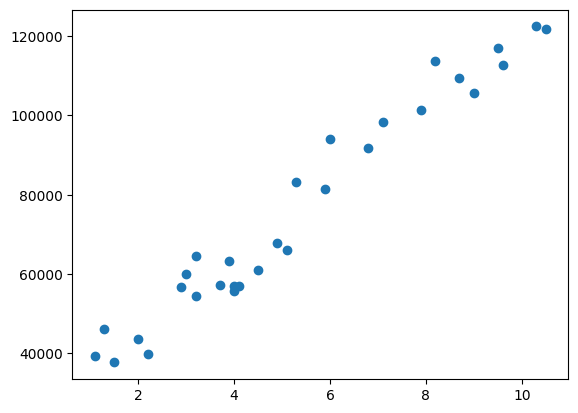

In [ ]:
X1 = df["YearsExperience"]
Y1 = df["Salary"]
plt.scatter(X1,Y1)
plt.show()

In [ ]:
#draw a straight line meeting some points in the middle of all the points.
#to predict new value,draw a line perpendicular to X towards the regression line.from there draw a line perpendicular to y.that is the predicted value

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=0)

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,Y_train)
Y_pred = model.predict(X_test)

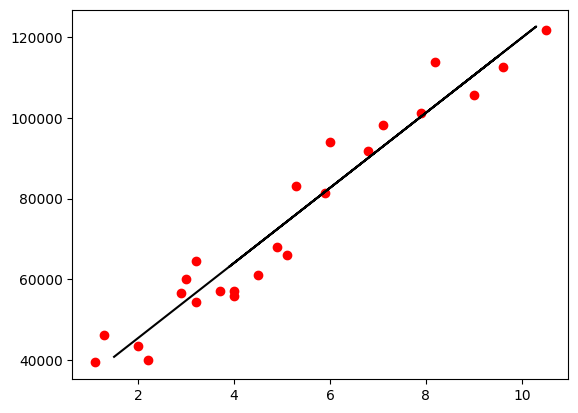

In [ ]:
plt.scatter(X_train,Y_train,color="red")
plt.plot(X_test,Y_pred,color="black")


In [ ]:
new =[[5]]
prediction = model.predict(new)
print(prediction)

[73342.97478427]


In [ ]:
print(model.predict([[6]]))

[82655.549911]


In [ ]:
df1=pd.DataFrame({"Actual":Y_test,"Predicted":Y_pred,"error":Y_pred-Y_test})
df1

,Actual,Predicted,error
0,37731.0,40748.961841,3017.961841
1,122391.0,122699.622956,308.622956
2,57081.0,64961.657170,7880.657170
3,63218.0,63099.142145,-118.857855
4,116969.0,115249.562855,-1719.437145
5,109431.0,107799.502753,-1631.497247


In [ ]:
#Performance Evaluation
    #MAE
    #MSE
    #RMSE
    #MAPE
    #R2 Score

In [ ]:
#MAE - Mean Absolute Error
 #actual value - Y
 #predicted vaue - Y'
 # error - Y -Y'
 # Absolute error = |Y -Y'|
 # Mean = sum of all observations / Total no.of observations
 # MAE = 1/N * ∑(|Y -Y'|)

In [ ]:
#MAPE - Mean Absolute Percentage Error
  #it should decrease

In [ ]:
#MSE - Mean Squared Error
 # error = Y - Y'
 #squared error = (Y - Y')^2
 # MSE = 1/N * ∑((Y -Y')^2)

In [ ]:
# RMSE - Root Mean Square error
  #   RMSE = √ (1/N * ∑((Y -Y')^2))

In [ ]:
from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(Y_test,Y_pred))

2446.1723690465055


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
print(mean_absolute_percentage_error(Y_test,Y_pred))

0.042009635296206715


In [ ]:
from sklearn.metrics import mean_squared_error
print(mean_squared_error(Y_test,Y_pred))

12823412.298126549


In [ ]:
data = mean_squared_error(Y_test,Y_pred)
print(np.sqrt(data))  #RMSE

3580.979237321343


In [ ]:
from sklearn.metrics import root_mean_squared_error
print(root_mean_squared_error(Y_test,Y_pred))

3580.979237321343


In [ ]:
#R2 Score
  # 1- (RSS/TSS)
  # RSS - Residual Sum of Squares
  # TSS - Total Sum of Squares

  # error = Y-Y'


  #  Y     Y'     E1=Y-Y'      E1^2    E2=Y-Mean(Y)     E2^2
  #  10    10       0           0          -20           400
  #  20    21      -1           1          -10           100
  #  30    28       2           4           0             0
  #  40    38       2           4           10           100
  #  50    49       1           1           20           400

  #MEAN(Y)=30

  #RSS = SUM OF E1^2 = 10
  #TSS = SUM OF E2^2 = 1000

  # R2 Score = 1 - (10/1000) = 0.99

  #MAPE - should decrease
  # R2 Score - should increase in regression

In [ ]:
from sklearn.metrics import r2_score
print(r2_score(Y_test,Y_pred))

0.988169515729126


In [ ]:
#line equation --> y=mx+c
#coef,intercept
print("Slope:",model.coef_)
print("Intercept:",model.intercept_)

Slope: [9312.57512673]
Intercept: 26780.09915062818


In [ ]:
x = 5
m = 9312.57512673
c = 26780.09915062818
y = m*x + c
print(y)

73342.97478427818
